# Зависимость объяснённой дисперсии от числа компонент PCA

**Герасимов Илья, группа 5030102/30401. Индивидуальное задание №49.**

Задача работы: найти минимальное число главных компонент, которое сохраняет 90%, 95% и 99% дисперсии данных.

На входе есть таблица с числовыми признаками. PCA позволяет заменить их меньшим числом новых признаков. Нужно определить, сколько компонент достаточно оставить для каждого из выбранных порогов.

Сначала разберём простой пример из четырёх точек. Потом проведём расчёт на Digits и Wine, построим графики и сравним результаты. Отдельно проверим, как на них влияет масштаб признаков.

Код, графики и результаты собраны в этом ноутбуке. Оба набора данных входят в scikit-learn, скачивать их отдельно не нужно.

In [1]:
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import Markdown, display
from matplotlib.ticker import MaxNLocator, PercentFormatter
from sklearn.datasets import load_digits, load_wine
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

%matplotlib inline

plt.rcParams.update({
    'font.family': 'DejaVu Sans',
    'font.size': 11,
    'axes.titlesize': 14,
    'axes.labelsize': 11,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'figure.dpi': 130,
    'savefig.dpi': 150,
    'axes.axisbelow': True,
})
BLUE = '#285D9F'
TEAL = '#087F82'
ORANGE = '#BF6134'
THRESHOLDS = (0.90, 0.95, 0.99)

display(pd.DataFrame({
    'Среда': ['Python', 'NumPy', 'pandas', 'Matplotlib', 'scikit-learn'],
    'Версия': [platform.python_version(), np.__version__, pd.__version__,
               matplotlib.__version__, sklearn.__version__],
}))

,Среда,Версия
0,Python,3.12.14
1,NumPy,2.3.5
2,pandas,2.2.3
3,Matplotlib,3.11.2
4,scikit-learn,1.9.1


## 1. Что показывает объяснённая дисперсия

Компонента PCA, по сути, это новый числовой признак. Он получается из исходных признаков с помощью взвешенной суммы.

Можно представить, что мы выбираем новые оси координат. Первую направляем туда, где данные имеют самый большой разброс. Вторую выбираем под прямым углом к первой, снова в направлении наибольшего доступного разброса. Каждое следующее направление выбираем перпендикулярно всем предыдущим.

У каждой компоненты есть своя дисперсия. Они упорядочены по убыванию. Чтобы узнать вклад одной компоненты, делим её дисперсию на сумму дисперсий всех компонент:

```text
r_j = lambda_j / (lambda_1 + lambda_2 + ... + lambda_d)
```

Здесь `lambda_j` обозначает дисперсию компоненты с номером `j`, `d` обозначает общее число компонент, а `r_j` показывает её долю в общей дисперсии.

Теперь складываем доли первых `k` компонент и получаем накопленную долю:

```text
R(k) = r_1 + r_2 + ... + r_k
```

Например, первая компонента дала 40%, вторая ещё 25%. Значит, вместе они объясняют 65% дисперсии.

В коде отдельные доли берутся из `explained_variance_ratio_`. Затем `np.cumsum` последовательно складывает их. По результату выбираем первое `k`, при котором достигнут нужный процент.

Сохранить 95% дисперсии не значит получить 95% точности. Мы пока смотрим только на разброс данных. Полезность оставшихся признаков для классификации нужно проверять отдельно.

In [2]:
def pca_profile(X):
    """Считаем доли дисперсии для всех компонент PCA."""
    X = np.asarray(X, dtype=np.float64)
    model = PCA(n_components=None, svd_solver='full', whiten=False).fit(X)
    ratio = model.explained_variance_ratio_
    return {'model': model, 'ratio': ratio, 'cumulative': np.cumsum(ratio)}


def minimum_components(cumulative, threshold):
    """Находим первое k, при котором достигнут нужный порог."""
    if not 0 < threshold <= 1:
        raise ValueError('Порог должен быть больше 0 и не больше 1.')
    reached = np.flatnonzero(np.asarray(cumulative) >= threshold - 1e-12)
    if reached.size == 0:
        raise ValueError('Указанный порог не достигается.')
    return int(reached[0] + 1)

## 2. Сначала проверим на простом примере

Возьмём четыре точки: `(-3, 0)`, `(3, 0)`, `(0, -1)` и `(0, 1)`.

По горизонтали точки разнесены сильнее, чем по вертикали. Поэтому уже можно ожидать, что первая компонента пойдёт вдоль горизонтальной оси.

Посчитаем точно. Среднее по обеим координатам равно нулю. Если делить на `n - 1 = 3`, дисперсия первой координаты будет 6, а второй 2/3. Ковариация равна нулю, поэтому главные направления здесь совпадают с исходными осями.

Доля первой компоненты:

```text
6 / (6 + 2/3) = 0,9 = 90%
```

Вторая добавляет оставшиеся 10%. Получается, для порога 90% хватит одной компоненты, а для 95% понадобятся обе.

Теперь проверим это через PCA.

In [3]:
toy = np.array([[-3, 0], [3, 0], [0, -1], [0, 1]], dtype=float)
toy_result = pca_profile(toy)
display(pd.DataFrame({
    'Компонента': [1, 2],
    'Дисперсия': toy_result['model'].explained_variance_,
    'Доля, %': 100 * toy_result['ratio'],
    'Накопленная доля, %': 100 * toy_result['cumulative'],
}).round(4))
np.testing.assert_allclose(toy_result['ratio'], [0.9, 0.1], atol=1e-12)
assert minimum_components(toy_result['cumulative'], 0.9) == 1
assert minimum_components(toy_result['cumulative'], 0.95) == 2

,Компонента,Дисперсия,"Доля, %","Накопленная доля, %"
0,1,6.0000,90.0,90.0
1,2,0.6667,10.0,100.0


## 3. Данные и порядок расчёта

**Digits** содержит 1797 изображений цифр размером 8x8. Для PCA каждое изображение превращается в строку из 64 чисел. Это яркости пикселей от 0 до 16. Все они измеряются в одной шкале, поэтому в основном расчёте оставляем их масштаб как есть.

**Wine** содержит 178 объектов и 13 химических характеристик. Здесь масштабы разные. Например, один признак может измеряться сотнями, а другой долями единицы. Перед PCA применяем `StandardScaler`: из каждого столбца вычитаем его среднее и делим значения на стандартное отклонение.

Дальше считаем все компоненты PCA, получаем долю дисперсии каждой из них и последовательно складываем эти доли. Так можно посмотреть результат для любого числа компонент. Пороги 90%, 95% и 99% заданы заранее.

В коде есть три настройки PCA:

- `n_components=None` оставляет все компоненты, чтобы увидеть всю кривую.
- `svd_solver='full'` задаёт полное разложение SVD, без случайного приближения.
- `whiten=False` оставляет координаты компонент без дополнительного приведения к единичной дисперсии.

Здесь изучаем сами наборы данных, поэтому используем все объекты. Метки классов в расчёт не входят. Если бы PCA было частью модели для предсказаний, масштабирование и PCA нужно было бы обучать только на обучающей выборке.

In [4]:
digits = load_digits()
wine = load_wine()
X_digits = digits.data.astype(np.float64)
X_wine = wine.data.astype(np.float64)
wine_scaler = StandardScaler()
X_wine_scaled = wine_scaler.fit_transform(X_wine)

datasets = {
    'Digits': X_digits,
    'Wine после стандартизации': X_wine_scaled,
}
results = {name: pca_profile(X) for name, X in datasets.items()}

display(pd.DataFrame([
    {'Данные': 'Digits', 'Объектов': len(X_digits), 'Признаков': X_digits.shape[1],
     'Постоянных столбцов': int(np.count_nonzero(np.ptp(X_digits, axis=0) == 0)),
     'Подготовка': 'Без изменения масштаба'},
    {'Данные': 'Wine', 'Объектов': len(X_wine), 'Признаков': X_wine.shape[1],
     'Постоянных столбцов': int(np.count_nonzero(np.ptp(X_wine, axis=0) == 0)),
     'Подготовка': 'StandardScaler'},
]))

,Данные,Объектов,Признаков,Постоянных столбцов,Подготовка
0,Digits,1797,64,3,Без изменения масштаба
1,Wine,178,13,0,StandardScaler


## 4. Сколько даёт каждая компонента отдельно

Сначала посмотрим на отдельные вклады. По горизонтали указан номер компоненты, по вертикали её доля дисперсии.

Первый столбец показывает вклад первой компоненты. Второй показывает только добавку от второй. Чтобы узнать результат для первых двух вместе, эти значения нужно сложить.

Если первые столбцы высокие, а остальные быстро уменьшаются, большую часть дисперсии можно сохранить небольшим числом компонент.

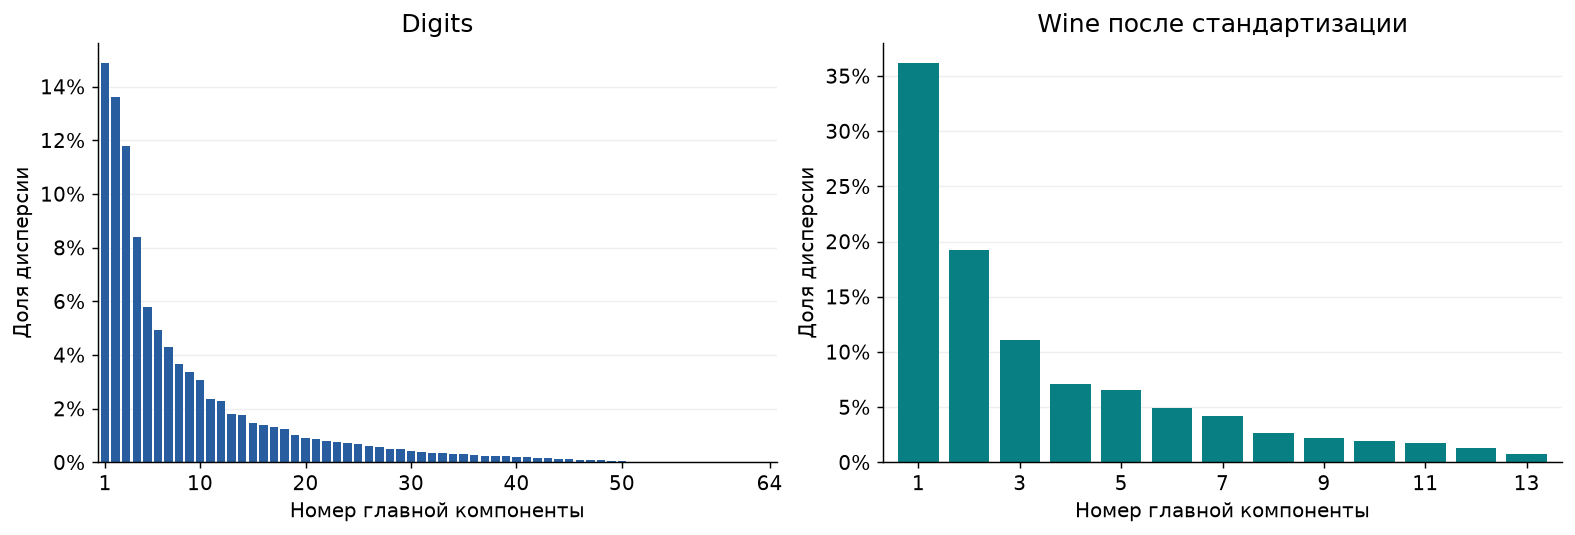

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
for ax, (name, result), color in zip(axes, results.items(), [BLUE, TEAL]):
    numbers = np.arange(1, len(result['ratio']) + 1)
    ax.bar(numbers, 100 * result['ratio'], color=color, width=0.8)
    ax.set(title=name, xlabel='Номер главной компоненты', ylabel='Доля дисперсии')
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
    ax.set_xticks([1, 10, 20, 30, 40, 50, 64] if len(numbers) == 64 else [1, 3, 5, 7, 9, 11, 13])
    ax.set_xlim(0.3, numbers[-1] + 0.7)
    ax.grid(axis='y', alpha=0.2)
plt.show()

In [6]:
for name, result in results.items():
    first = 100 * result['ratio'][0]
    first_two = 100 * result['cumulative'][1]
    display(Markdown(
        f'**{name}:** первая компонента объясняет {first:.2f}%, '
        f'первые две вместе дают {first_two:.2f}% дисперсии.'
    ))

**Digits:** первая компонента объясняет 14.89%, первые две вместе дают 28.51% дисперсии.

**Wine после стандартизации:** первая компонента объясняет 36.20%, первые две вместе дают 55.41% дисперсии.

## 5. Сколько компонент нужно оставить

Теперь складываем доли и строим накопленную кривую `R(k)`. По горизонтали указано, сколько компонент оставили. По вертикали видно, какую часть дисперсии они объясняют вместе.

Пунктиром отмечены пороги 90%, 95% и 99%. Оранжевая точка показывает минимальное число компонент для порога 95%.

Кривая может идти вверх или оставаться на месте. Уменьшиться она не может, потому что каждая новая компонента добавляет неотрицательную долю. Если взять все компоненты, получим 100% с небольшой погрешностью округления.

При этом некоторые последние компоненты могут ничего не добавлять. Такое бывает, если часть исходных столбцов постоянна или зависит от других столбцов.

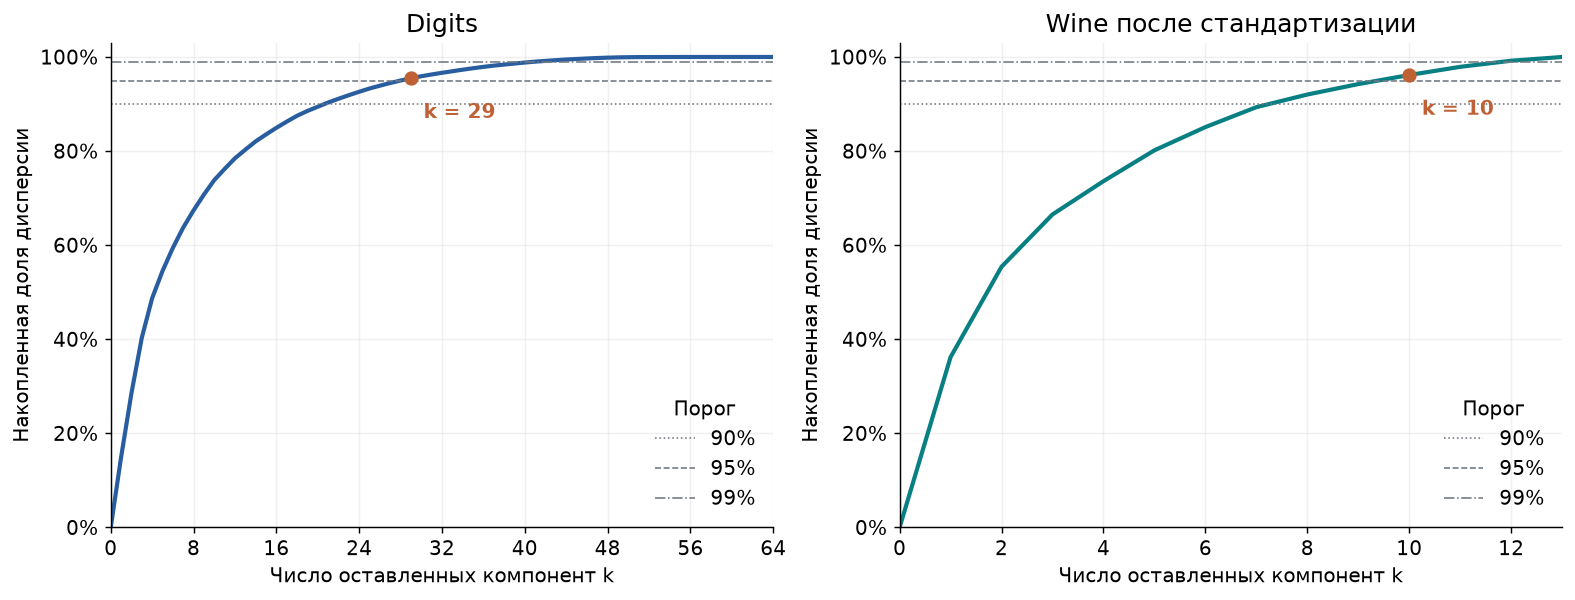

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), layout='constrained')
for ax, (name, result), color in zip(axes, results.items(), [BLUE, TEAL]):
    k_values = np.arange(len(result['ratio']) + 1)
    cumulative = np.r_[0, 100 * result['cumulative']]
    ax.plot(k_values, cumulative, color=color, linewidth=2.3)
    for threshold, linestyle in zip(THRESHOLDS, [':', '--', '-.']):
        ax.axhline(threshold * 100, color='#727A83', linestyle=linestyle,
                   linewidth=0.9, label=f'{threshold:.0%}')
    k95 = minimum_components(result['cumulative'], 0.95)
    value95 = 100 * result['cumulative'][k95 - 1]
    ax.scatter(k95, value95, s=48, color=ORANGE, zorder=4)
    ax.annotate(f'k = {k95}', (k95, value95), xytext=(7, -22),
                textcoords='offset points', color=ORANGE, fontweight='bold')
    ax.set(title=name, xlabel='Число оставленных компонент k',
           ylabel='Накопленная доля дисперсии', ylim=(0, 103),
           xlim=(0, len(result['ratio'])))
    ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=8))
    ax.grid(alpha=0.18)
    ax.legend(title='Порог', loc='lower right', frameon=False)
plt.show()

In [8]:
rows = []
for name, result in results.items():
    d = len(result['ratio'])
    for threshold in THRESHOLDS:
        k = minimum_components(result['cumulative'], threshold)
        rows.append({
            'Данные': name,
            'Порог, %': int(round(threshold * 100)),
            'Минимальное k': k,
            'Исходных признаков': d,
            'Доля при k-1, %': 100 * (result['cumulative'][k - 2] if k > 1 else 0),
            'Доля при k, %': 100 * result['cumulative'][k - 1],
        })
summary = pd.DataFrame(rows)
display(summary.round(3))

,Данные,"Порог, %",Минимальное k,Исходных признаков,"Доля при k-1, %","Доля при k, %"
0,Digits,90,21,64,89.430,90.320
1,Digits,95,29,64,94.990,95.480
2,Digits,99,41,64,98.820,99.010
3,Wine после стандартизации,90,8,13,89.337,92.018
4,Wine после стандартизации,95,10,13,94.240,96.170
5,Wine после стандартизации,99,12,13,97.907,99.205


В таблице рядом стоят результаты для `k-1` и `k` компонент. Так видно, почему выбрано именно это число: при `k-1` нужного процента ещё нет, а при `k` он уже достигнут.

Долю дисперсии не нужно путать с долей оставленных координат. Чтобы сохранить 95% дисперсии, необязательно оставлять 95% от исходного числа признаков.

In [9]:
for name, result in results.items():
    d = len(result['ratio'])
    k95 = minimum_components(result['cumulative'], 0.95)
    kept = 100 * result['cumulative'][k95 - 1]
    display(Markdown(
        f'**{name}:** чтобы сохранить 95% дисперсии, нужно **{k95} компонент из {d}**. '
        f'Они объясняют {kept:.2f}% дисперсии. '
        f'Координат стало меньше на {100 * (1 - k95 / d):.1f}%. '
        f'Этот процент показывает, насколько уменьшилось число координат.'
    ))

**Digits:** чтобы сохранить 95% дисперсии, нужно **29 компонент из 64**. Они объясняют 95.48% дисперсии. Координат стало меньше на 54.7%. Этот процент показывает, насколько уменьшилось число координат.

**Wine после стандартизации:** чтобы сохранить 95% дисперсии, нужно **10 компонент из 13**. Они объясняют 96.17% дисперсии. Координат стало меньше на 23.1%. Этот процент показывает, насколько уменьшилось число координат.

## 6. А что будет без масштабирования

Теперь возьмём те же данные Wine и уберём `StandardScaler`. То есть объекты остаются теми же, а признаки возвращаются в исходные единицы измерения.

Если у одного столбца дисперсия намного больше, чем у остальных, он может почти полностью определять результат PCA. Проверим, получится ли это на Wine.

На графике будут две кривые. Их проценты считаются от разной общей дисперсии: до стандартизации и после неё. Поэтому по одной высоте кривой нельзя решить, какой вариант лучше сохранил полезную информацию.

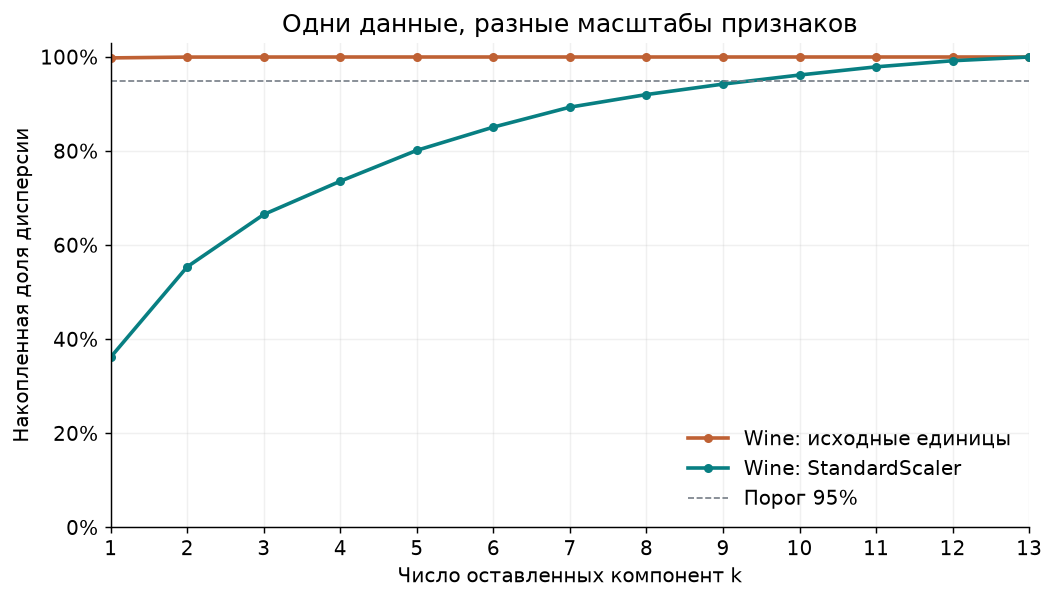

,Подготовка Wine,"Первая компонента, %",k для 90%,k для 95%,k для 99%
0,Исходные единицы,99.809,1,1,1
1,StandardScaler,36.199,8,10,12


У признака **proline** самая большая дисперсия в исходных единицах: 99166.7. Она составляет 99.77% суммы дисперсий исходных столбцов. Поэтому без масштабирования первая компонента в основном отражает разброс этого признака.

In [10]:
wine_raw_result = pca_profile(X_wine)
wine_scaled_result = results['Wine после стандартизации']

fig, ax = plt.subplots(figsize=(8, 4.5), layout='constrained')
for label, result, color in [
    ('Wine: исходные единицы', wine_raw_result, ORANGE),
    ('Wine: StandardScaler', wine_scaled_result, TEAL),
]:
    ax.plot(np.arange(1, 14), 100 * result['cumulative'], marker='o',
            markersize=4, linewidth=2, label=label, color=color)
ax.axhline(95, color='#727A83', linestyle='--', linewidth=0.9, label='Порог 95%')
ax.set(title='Одни данные, разные масштабы признаков',
       xlabel='Число оставленных компонент k', ylabel='Накопленная доля дисперсии',
       xlim=(1, 13), ylim=(0, 103), xticks=np.arange(1, 14))
ax.yaxis.set_major_formatter(PercentFormatter(xmax=100, decimals=0))
ax.grid(alpha=0.18)
ax.legend(loc='lower right', frameon=False)
plt.show()

scale_rows = []
for label, result in [('Исходные единицы', wine_raw_result),
                      ('StandardScaler', wine_scaled_result)]:
    scale_rows.append({
        'Подготовка Wine': label,
        'Первая компонента, %': 100 * result['ratio'][0],
        'k для 90%': minimum_components(result['cumulative'], 0.90),
        'k для 95%': minimum_components(result['cumulative'], 0.95),
        'k для 99%': minimum_components(result['cumulative'], 0.99),
    })
display(pd.DataFrame(scale_rows).round(3))

raw_variances = X_wine.var(axis=0, ddof=1)
largest = int(np.argmax(raw_variances))
display(Markdown(
    f'У признака **{wine.feature_names[largest]}** самая большая дисперсия '
    f'в исходных единицах: {raw_variances[largest]:.1f}. '
    f'Она составляет {100 * raw_variances[largest] / raw_variances.sum():.2f}% '
    f'суммы дисперсий исходных столбцов. '
    'Поэтому без масштабирования первая компонента в основном отражает разброс этого признака.'
))

После стандартизации все непостоянные признаки начинают с одинаковой дисперсии. Теперь большой масштаб одного столбца уже не определяет почти весь результат.

Для Wine это имеет смысл, потому что химические характеристики измеряются в разных единицах. Но масштабирование не стоит применять автоматически в любой задаче. Сначала нужно понять, важен ли сам исходный масштаб признаков.

Ещё нельзя сравнивать Digits и Wine только по числу оставшихся компонент. В одном наборе было 64 исходных признака, в другом 13. Связи между признаками тоже разные.

## 7. Проверим, правильно ли всё посчитано

Дополнительно проверим расчёт независимо от графиков.

Сначала отдельно считаем собственные значения ковариационной матрицы через `np.linalg.eigvalsh`. Они должны совпасть с дисперсиями компонент, которые вернул PCA.

Потом проверяем, что доли в сумме дают единицу, накопленная кривая не убывает, а выбранное число компонент действительно минимально для каждого порога.

In [11]:
profiles_to_check = {
    'Численный пример': (toy, toy_result),
    'Digits': (X_digits, results['Digits']),
    'Wine после стандартизации': (X_wine_scaled, wine_scaled_result),
    'Wine без стандартизации': (X_wine, wine_raw_result),
}
checks = []
for name, (X, result) in profiles_to_check.items():
    ratio, cumulative = result['ratio'], result['cumulative']
    covariance = np.cov(X, rowvar=False, ddof=1)
    eigenvalues = np.linalg.eigvalsh(covariance)[::-1]
    pca_variances = result['model'].explained_variance_
    np.testing.assert_allclose(pca_variances, eigenvalues, rtol=1e-9, atol=1e-10)
    np.testing.assert_allclose(pca_variances.sum(), X.var(axis=0, ddof=1).sum(), rtol=1e-10)
    np.testing.assert_allclose(ratio.sum(), 1.0, atol=1e-12)
    assert np.all(ratio >= -1e-12)
    assert np.all(np.diff(ratio) <= 1e-12)
    assert np.all(np.diff(cumulative) >= -1e-12)
    for threshold in THRESHOLDS:
        k = minimum_components(cumulative, threshold)
        assert cumulative[k - 1] >= threshold - 1e-12
        if k > 1:
            assert cumulative[k - 2] < threshold - 1e-12
    checks.append({'Данные': name,
                   'Сумма долей': ratio.sum(),
                   'Макс. отличие дисперсий': np.max(np.abs(pca_variances - eigenvalues)),
                   'Проверки': 'Пройдены'})
display(pd.DataFrame(checks))

,Данные,Сумма долей,Макс. отличие дисперсий,Проверки
0,Численный пример,1.0,8.881784e-16,Пройдены
1,Digits,1.0,3.126388e-13,Пройдены
2,Wine после стандартизации,1.0,4.440892e-15,Пройдены
3,Wine без стандартизации,1.0,4.365575e-11,Пройдены


## 8. Что получилось

На Digits для сохранения 95% дисперсии хватило 29 компонент из 64. На Wine после стандартизации понадобилось 10 из 13. Значит, одно и то же требование по дисперсии может давать разное число компонент.

При переходе от 95% к 99% компонент нужно заметно больше. У последних компонент маленький отдельный вклад, поэтому дополнительные проценты набираются медленнее.

Ещё результат сильно зависит от масштаба. У Wine без стандартизации первая компонента объяснила почти всю дисперсию. Но это связано с большим разбросом отдельных исходных признаков. Из этого не следует, что остальные химические характеристики не нужны.

Число компонент выбираем по накопленной кривой. Сначала задаём нужную долю дисперсии, затем находим минимальное число компонент, при котором она достигнута. Так решение можно объяснить конкретными числами.

Выводы относятся к этим двум наборам и выбранной подготовке данных. Если дальше нужно решать задачу классификации, одного показателя дисперсии недостаточно. Нужно отдельно проверить, как выбранное число компонент влияет на качество модели.

In [12]:
digits_k = [minimum_components(results['Digits']['cumulative'], t) for t in THRESHOLDS]
wine_k = [minimum_components(wine_scaled_result['cumulative'], t) for t in THRESHOLDS]
display(Markdown(
    f'**Итог по числам.** Для Digits нужно {digits_k[0]}, {digits_k[1]} и {digits_k[2]} '
    f'компонент из 64 для 90%, 95% и 99%. '
    f'Для Wine после стандартизации нужно {wine_k[0]}, {wine_k[1]} и {wine_k[2]} из 13. '
    'Одинаковый порог по дисперсии дал разное число компонент.'
))

**Итог по числам.** Для Digits нужно 21, 29 и 41 компонент из 64 для 90%, 95% и 99%. Для Wine после стандартизации нужно 8, 10 и 12 из 13. Одинаковый порог по дисперсии дал разное число компонент.

## Источники

- [PCA в scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html). Как считаются дисперсии компонент и их доли.
- [Набор Digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html). Описание данных.
- [Набор Wine](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html). Описание данных.
- [StandardScaler](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html). Как работает стандартизация признаков.